In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
def load_dataset(file_path, target_column):
  df = pd.read_csv(file_path)
  X = df.drop(columns=[target_column])
  y = df[target_column]
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42, stratify=y
  )
  return df, X_train, X_test, y_train, y_test

In [3]:
def plot_pairplot(df, target_column):
  sns.pairplot(df, hue=target_column, diag_kind="kde")
  plt.suptitle("Pairplot of Features by Class", y=1.02)
  plt.show()

In [4]:
def scale_features(X_train, X_test):
  # Fit the scaler on the training data only
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)
  return X_train_scaled, X_test_scaled

In [5]:
def print_scores(name, y_test, y_pred):
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, average="macro")
  recall = recall_score(y_test, y_pred, average="macro")
  f1 = f1_score(y_test, y_pred, average="macro")
  print(f"\n=== {name} ===")
  print(f"Accuracy: {accuracy:.4f}")
  print(f"Precision (macro): {precision:.4f}")
  print(f"Recall (macro): {recall:.4f}")
  print(f"F1 (macro): {f1:.4f}")
  print("\nClassification report:")
  print(classification_report(y_test, y_pred))
  return {
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1": f1,
  }

In [6]:
def train_classifier(name, model, X_train, X_test, y_train, y_test):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  scores = print_scores(name, y_test, y_pred)
  return y_pred, scores

In [7]:
def plot_confusion_matrices(y_test, all_predictions, class_names):
  fig, axes = plt.subplots(1, len(all_predictions), figsize=(12, 5))

  for i, name in enumerate(all_predictions):
    cm = confusion_matrix(y_test, all_predictions[name], labels=class_names)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i],
    )
    axes[i].set_title(f"{name}: Confusion Matrix")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

  plt.tight_layout()
  plt.show()

In [8]:
def plot_decision_boundaries(
    X_train, y_train, models, feature_names, class_names, feature_indices
):
  # Decision boundaries need two features, so the models are refit on those
  X_2d = X_train[:, feature_indices]
  y_codes = pd.Categorical(y_train, categories=class_names).codes

  x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
  y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
  xx, yy = np.meshgrid(
      np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300)
  )
  grid_points = np.c_[xx.ravel(), yy.ravel()]

  fig, axes = plt.subplots(1, len(models), figsize=(14, 6))

  for i, name in enumerate(models):
    model = clone(models[name])
    model.fit(X_2d, y_codes)
    Z = model.predict(grid_points).reshape(xx.shape)

    axes[i].contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=pd.Categorical.from_codes(y_codes, class_names),
        palette="viridis",
        edgecolor="black",
        ax=axes[i],
    )
    axes[i].set_title(f"{name}: Decision Boundary")
    axes[i].set_xlabel(f"{feature_names[feature_indices[0]]} (scaled)")
    axes[i].set_ylabel(f"{feature_names[feature_indices[1]]} (scaled)")

  plt.tight_layout()
  plt.show()

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


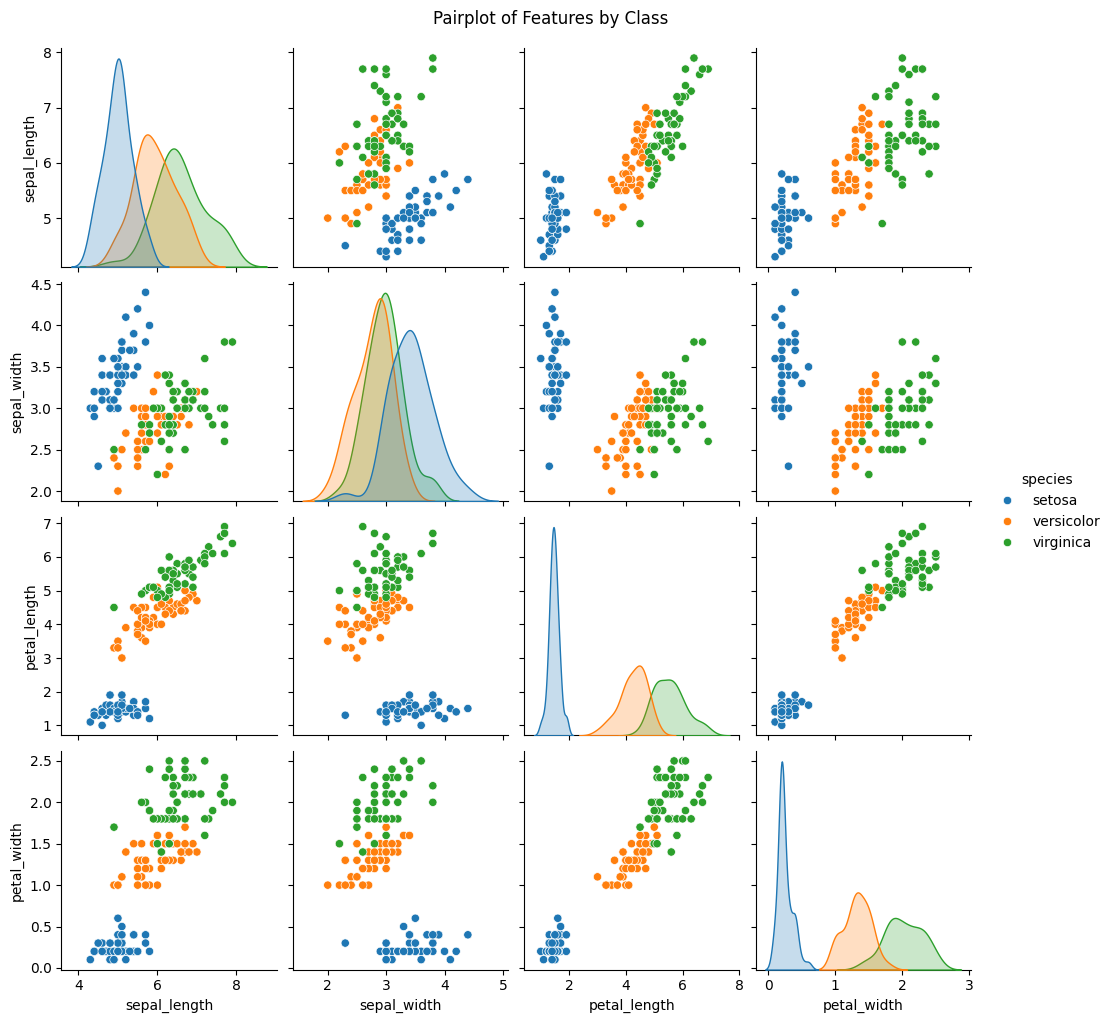

In [9]:
file_path = "bechmark.csv"
target_column = "species"

df, X_train, X_test, y_train, y_test = load_dataset(file_path, target_column)
class_names = sorted(y_train.unique())
print(df.head())
print(df[target_column].value_counts())
plot_pairplot(df, target_column)

In [10]:
# Standardize the features
X_train_scaled, X_test_scaled = scale_features(X_train, X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

all_predictions = {}
all_scores = {}
for name in models:
  all_predictions[name], all_scores[name] = train_classifier(
      name, models[name], X_train_scaled, X_test_scaled, y_train, y_test
  )

print("\n=== Benchmark Summary ===")
print(pd.DataFrame(all_scores).T.round(4))


=== Logistic Regression ===
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1 (macro): 0.9333

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


=== Decision Tree ===
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1 (macro): 0.9333

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93

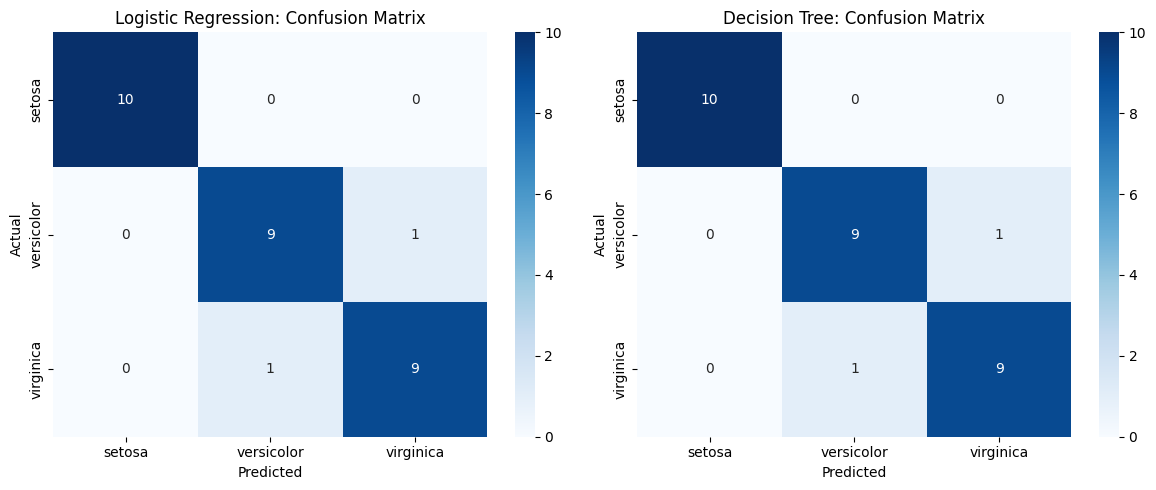

In [11]:
plot_confusion_matrices(y_test, all_predictions, class_names)

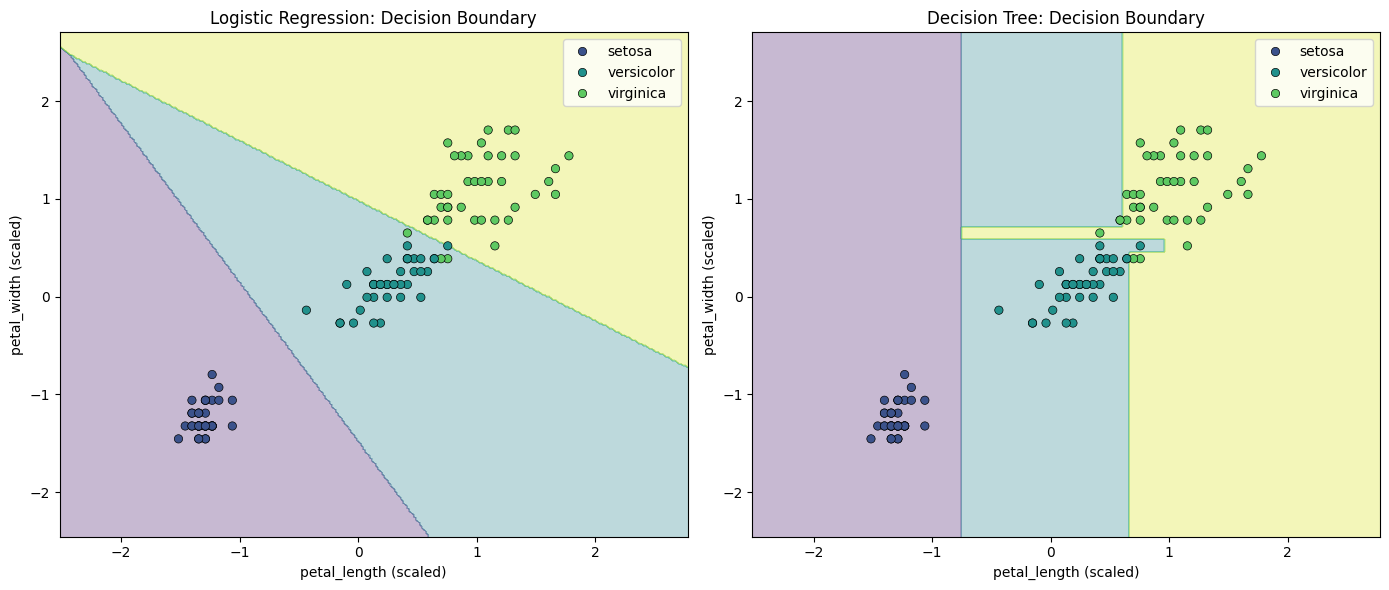

In [12]:
# Use the two petal features for the decision boundary plots
plot_decision_boundaries(
    X_train_scaled, y_train, models, list(X_train.columns), class_names,
    feature_indices=[2, 3],
)